# Ny notatbok

Skriv kode i cellene under, og kjør dem med **Shift+Enter**.

(np.float64(-0.5), np.float64(837.5), np.float64(1117.5), np.float64(-0.5))

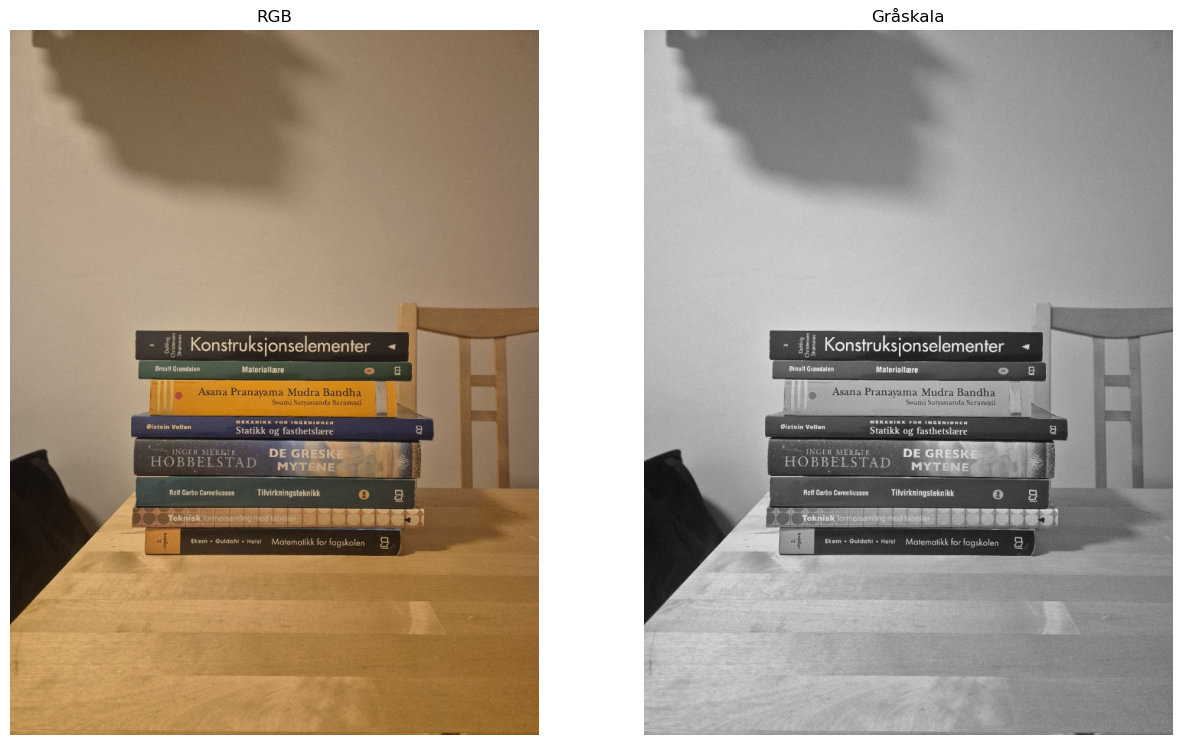

In [19]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact
import fargelab

IMAGE_NAME = 'stack_1.jpg'
# IMAGE_NAME = 'stack_2.jpg'
# IMAGE_NAME = 'stack_3.jpg'
# IMAGE_NAME = 'stack_4.jpg'
# IMAGE_NAME = 'stack_5.jpg'
# IMAGE_NAME = 'stack_6.jpg'
# IMAGE_NAME = 'stack_7.jpg'
# IMAGE_NAME = 'stack_8.jpg'

# Styrke på fargeendring for å detektere en bok
EDGE_STRENGTH_THRESHOLD = 100
# Grenseverdi for horisontal lengde på kanten mellom to bøker
MIN_EDGE_LENGTH_PX = 120
# Minimums tykkelse for en bok.
MIN_BOOK_THICKNESS_PX = 15

image       = cv2.imread(IMAGE_NAME)
img_gray    = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


# ==============================================================================================================
plt.figure(figsize=[15, 10])
plt.subplot(121); plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); plt.title("RGB"); plt.axis('off')
plt.subplot(122); plt.imshow(img_gray, cmap='gray'); plt.title("Gråskala"); plt.axis('off')


(np.float64(-0.5), np.float64(837.5), np.float64(1117.5), np.float64(-0.5))

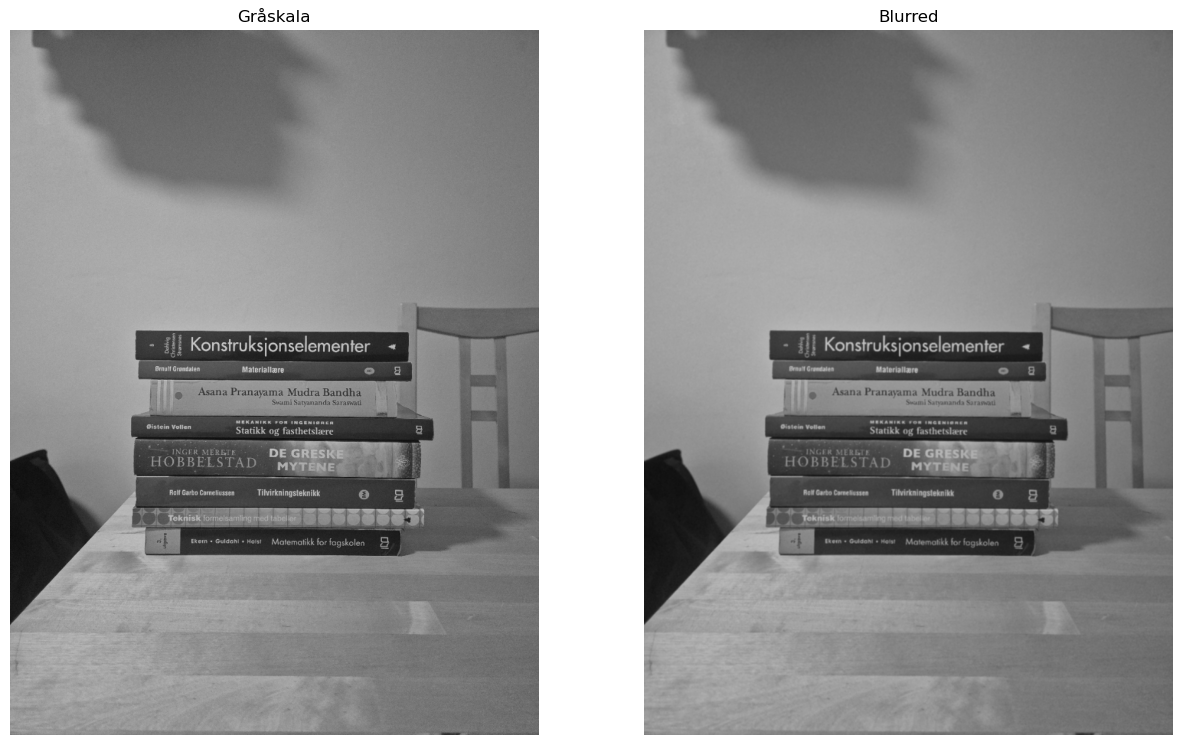

In [20]:
blurred_image = cv2.GaussianBlur(img_gray, (3, 3), 0)


# ==============================================================================================================
plt.figure(figsize=[15, 10])
plt.subplot(121); plt.imshow(cv2.cvtColor(img_gray, cv2.COLOR_BGR2RGB)); plt.title("Gråskala"); plt.axis('off')
plt.subplot(122); plt.imshow(cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB)); plt.title("Blurred"); plt.axis('off')

(np.float64(-0.5), np.float64(837.5), np.float64(1117.5), np.float64(-0.5))

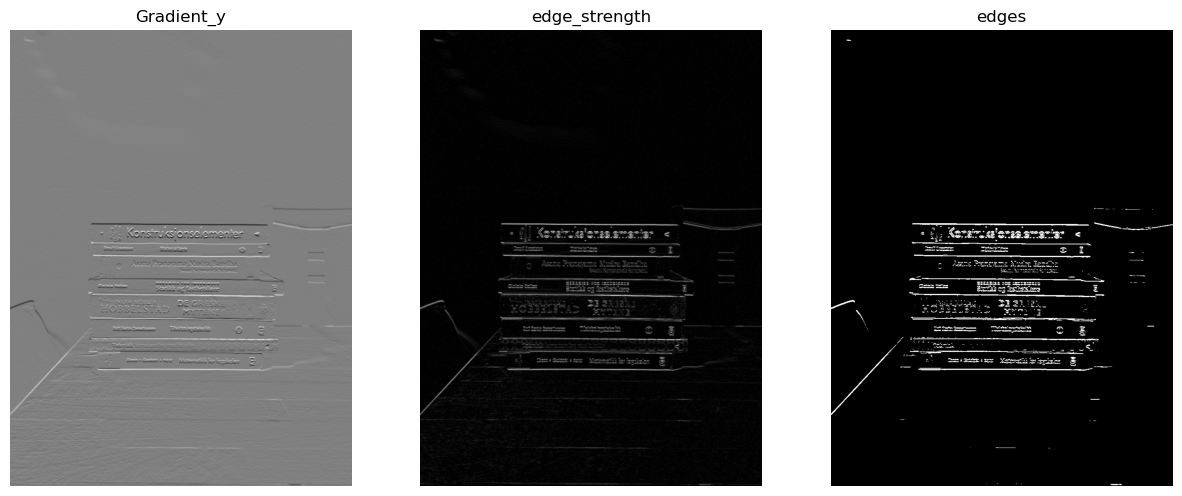

In [21]:
# Sobel glir en kernel vertikalt over bildet for å finne skarpe horisontal pikseloverganger. 
# Lager binært bilde. Markerer alle kanter over EDGE_STRENGTH_THRESHOLD i hvitt. 
gradient_y = cv2.Sobel(blurred_image, cv2.CV_32F, 0, 1, ksize=3)
edge_strength = np.abs(gradient_y)
edges = (edge_strength > EDGE_STRENGTH_THRESHOLD).astype(np.uint8) * 255


# ==============================================================================================================
plt.figure(figsize=[15, 10])
plt.subplot(131);plt.imshow(gradient_y, cmap='gray');plt.title("Gradient_y"); plt.axis('off')
plt.subplot(132);plt.imshow(edge_strength, cmap='gray');plt.title("edge_strength"); plt.axis('off')
plt.subplot(133); plt.imshow(edges, cmap='gray'); plt.title("edges"); plt.axis('off')

kernel (1x120) =  [[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
  1 1 1 1 1 1 1 1 1 1 1 1]]


(np.float64(-0.5), np.float64(837.5), np.float64(1117.5), np.float64(-0.5))

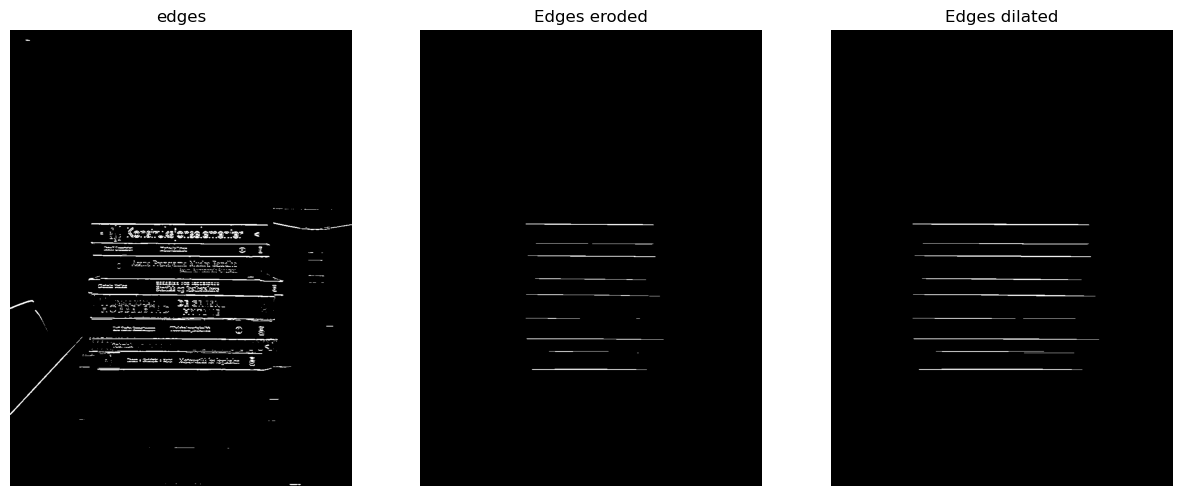

In [22]:
# Lager en kernel som er MIN_EDGE_LENGTH_PX (1 x 120 piksler) bred for å fjerne skrift/støy
# og alt som ikke er lange vannrette linjer.
#                                                                 <-- 120 -->   
kernel = np.ones((1, MIN_EDGE_LENGTH_PX), np.uint8)     # [[111..................1111]] 

edges_eroded = cv2.erode(edges, kernel)
edges_ = cv2.dilate(edges_eroded, kernel)


# ==============================================================================================================
print("kernel (1x120) = ", kernel)
edges_dilated = cv2.dilate(edges_, kernel)
plt.figure(figsize=[15, 10])
plt.subplot(131); plt.imshow(edges, cmap='gray'); plt.title("edges"); plt.axis('off')
plt.subplot(132); plt.imshow(edges_eroded, cmap='gray'); plt.title("Edges eroded"); plt.axis('off')
plt.subplot(133); plt.imshow(edges_, cmap='gray'); plt.title("Edges dilated"); plt.axis('off')

In [23]:
# cv2.findContours finner sporer omrissene av alle sammenhengende hvite pikselområder. Kantlinjer blir konturer.
# cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE - henter kun yttergrenser,
# og komprimerer rette horisontale linjestykker og returnerer endepunkter --> en liste med x,y- korrdinater til kantlinjer.
contours, _ = cv2.findContours(edges_, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

boundaries = []                                     # For- loopen lager en liste med tupler til 'boundaries'.
for contour in contours:                            
    x, y, width, height = cv2.boundingRect(contour)     # finne rektangulære omriss som omslutter linjene.
    boundaries.append((y + height // 2, x, x + width))  # Beregner og legger til senterlinje omrissene. 
boundaries.sort()

books = []
for (upper_y, _, _), (lower_y, _, _) in zip(boundaries[:-1], boundaries[1:]):   # looper gjennom boundaries
    if lower_y - upper_y >= MIN_BOOK_THICKNESS_PX:                              # Ser om avstanden mellom linjene
        books.append((upper_y, lower_y))                                        # er > MIN_BOOK_THICKNESS_PX 
                                                                                # og legger det til som bok i books listen.
print(f"{IMAGE_NAME}: {len(books)} books detected.")

# ==============================================================================================================

stack_1.jpg: 8 books detected.


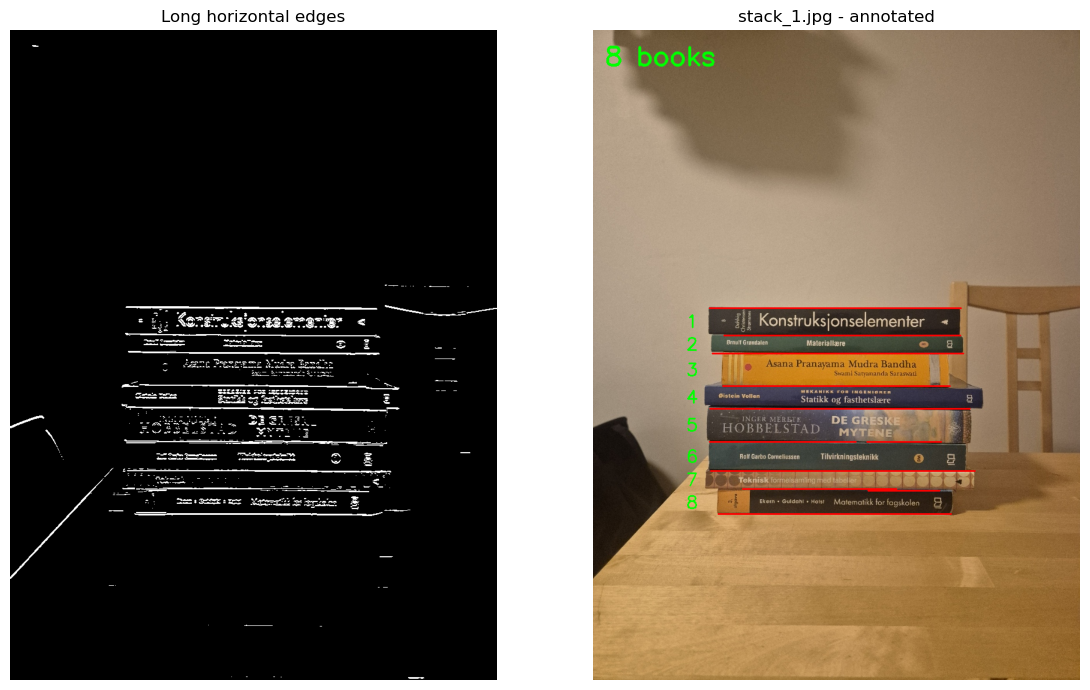

In [24]:
# Annoterer på en kopi av originale bildet.
annotated_image = image.copy()
stack_left = min(left for _, left, _ in boundaries)
for boundary_y, left, right in boundaries:
    cv2.line(annotated_image, (left, boundary_y), (right, boundary_y), (0, 0, 255), 2)
for number, (upper_y, lower_y) in enumerate(books, start=1):
    cv2.putText(annotated_image, str(number), (stack_left - 40, (upper_y + lower_y) // 2 + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)
cv2.putText(annotated_image, f"{len(books)} books", (20, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 3)

figure, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Long horizontal edges")
axes[1].imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"{IMAGE_NAME} - annotated")
axes[0].axis("off")
axes[1].axis("off")
plt.tight_layout()
plt.show()
